- **Гипотеза 3.** Можно ли увеличить количество аренды велосипедов, если будет путь по разным food trip.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

- читаю csv файл '../../../data_additional/point_of_interest.csv'

In [2]:
point_of_interest = pd.read_csv('../../../data_additional/point_of_interest.csv')
point_of_interest

,start_station_id,category,name_build,start_lat,start_lng
0,30200,place_of_worship,Methodist Protestant Church,38.896501,-77.024143
1,30200,kindergarten,Georgetown Hill Early Childhood Center,38.895100,-77.023200
2,30200,kindergarten,Just Us Kids Child Development Center,38.894600,-77.020700
3,30200,theatre,Shakespeare Theatre Company - Klein Theater,38.895734,-77.022132
4,30200,cafe,Gregorys Coffee,38.895972,-77.021713
...,...,...,...,...,...
34392,33200,bench,NaN,38.894267,-77.038270
34393,33200,bench,NaN,38.897443,-77.036620
34394,33200,bench,NaN,38.897445,-77.036499
34395,33200,bench,NaN,38.896953,-77.036979


- смотрю уникальные категории точек интереса

In [3]:
data = [point for point in point_of_interest['category'].unique()]

In [4]:
data

['place_of_worship',
 'kindergarten',
 'theatre',
 'cafe',
 'bank',
 'tourist',
 'atm',
 'restaurant',
 'fast_food',
 'bar',
 'pub',
 'bicycle_rental',
 'post_box',
 'arts_centre',
 'drinking_water',
 'bench',
 'waste_basket',
 'language_school',
 'bicycle_parking',
 'fountain',
 'post_office',
 'toilets',
 'parking',
 'parking_entrance',
 'charging_station',
 'loading_dock',
 'school',
 'car_sharing',
 'cinema',
 'ice_cream',
 'car_rental',
 'border_control',
 'clinic',
 'marketplace',
 'motorcycle_parking',
 'vending_machine',
 'doctors',
 'cloakroom',
 'parcel_locker',
 'animal_boarding',
 'bicycle_repair_station',
 'recycling',
 'veterinary',
 'pharmacy',
 'childcare',
 'waste_disposal',
 'clock',
 'bureau_de_change',
 'dentist',
 'reception_desk',
 'fuel',
 'biergarten',
 'food_court',
 'public_bookcase',
 'fire_station',
 'table',
 'police',
 'marker',
 'social_facility',
 'library',
 'university',
 'post_depot',
 'parking_space',
 'social_centre',
 'bbq',
 'hookah_lounge',
 'vac

- выбрал только те точки, которые связаны с едой

In [5]:
food_categories = [
    "restaurant",
    "fast_food",
    "cafe",
    "food_court",
    "ice_cream",
    "catering",
    "bar",
    "pub",
    "biergarten",
    "hookah_lounge",
    "marketplace",
    "convenience",
    "drinking_water",
    "food_sharing",
    "watering_place",
    "bbq"
]

- оставляю только те точки которые входят в food_categories

In [6]:
food_categories = point_of_interest[point_of_interest['category'].isin(food_categories)]
food_categories

,start_station_id,category,name_build,start_lat,start_lng
4,30200,cafe,Gregorys Coffee,38.895972,-77.021713
8,30200,restaurant,minibar by José Andrés,38.896319,-77.023576
10,30200,fast_food,Jacks Famous Deli,38.894494,-77.020710
11,30200,fast_food,Potbelly,38.894289,-77.021418
13,30200,cafe,Starbucks,38.894168,-77.021712
...,...,...,...,...,...
34360,33200,fast_food,Chopt,38.898905,-77.040419
34361,33200,cafe,Starbucks,38.898857,-77.040261
34362,33200,cafe,Naan & Beyond,38.898792,-77.040089
34388,33200,restaurant,Immigrant Food,38.899282,-77.040078


- смотрю сколько получилось точек интереса (используя value_counts())

In [7]:
food_categories['category'].value_counts()

category
restaurant        4618
fast_food         2426
cafe              1500
bar                721
drinking_water     391
pub                246
ice_cream          192
marketplace         64
food_court          48
bbq                 46
catering            12
hookah_lounge       11
biergarten           6
food_sharing         1
watering_place       1
convenience          1
Name: count, dtype: int64

- делаю группировку по start_station_id и category, считаю количество name_build и сбрасываю индексы

In [8]:
count_food_builds = food_categories.groupby(['start_station_id', 'category'])['name_build'].count().reset_index()
count_food_builds

,start_station_id,category,name_build
0,30200,bar,4
1,30200,cafe,4
2,30200,drinking_water,0
3,30200,fast_food,10
4,30200,pub,1
...,...,...,...
2174,32608,marketplace,1
2175,32608,restaurant,3
2176,33200,cafe,9
2177,33200,fast_food,3


- делаю функцию которая группирует по start_station_id и считает сумму по name_build

In [9]:
def count_total_food(df):
    return df.groupby('start_station_id')['name_build'].sum()

- создаю словарь

In [10]:
total_food_point = {}

- пишу цикл, который подсчитает сумму точек интереса

In [11]:
for station_id in count_food_builds['start_station_id'].unique():
    temp_df = count_food_builds[count_food_builds['start_station_id'] == station_id]
    total = count_total_food(temp_df)
    total_food_point[int(station_id)] = int(total.values[0])

- вывожу результат

In [12]:
total_food_point

{30200: 37,
 30201: 72,
 31000: 13,
 31001: 4,
 31002: 32,
 31003: 11,
 31004: 0,
 31005: 35,
 31006: 80,
 31007: 22,
 31009: 8,
 31010: 2,
 31011: 19,
 31012: 15,
 31013: 12,
 31014: 48,
 31015: 56,
 31016: 21,
 31017: 20,
 31018: 20,
 31019: 22,
 31020: 19,
 31021: 36,
 31022: 39,
 31023: 15,
 31024: 10,
 31025: 8,
 31026: 21,
 31027: 36,
 31028: 6,
 31029: 1,
 31030: 6,
 31031: 10,
 31032: 4,
 31033: 1,
 31034: 25,
 31035: 5,
 31036: 5,
 31037: 50,
 31038: 7,
 31039: 30,
 31040: 16,
 31041: 23,
 31042: 30,
 31043: 3,
 31044: 21,
 31045: 20,
 31046: 8,
 31047: 6,
 31048: 10,
 31049: 66,
 31050: 0,
 31051: 2,
 31052: 3,
 31053: 4,
 31055: 5,
 31057: 0,
 31058: 8,
 31060: 4,
 31061: 0,
 31062: 2,
 31065: 12,
 31066: 1,
 31067: 21,
 31068: 5,
 31069: 4,
 31071: 12,
 31073: 3,
 31074: 0,
 31075: 0,
 31076: 10,
 31077: 0,
 31079: 4,
 31081: 15,
 31082: 13,
 31083: 2,
 31084: 18,
 31085: 5,
 31086: 13,
 31087: 1,
 31088: 2,
 31089: 20,
 31091: 0,
 31092: 20,
 31094: 9,
 31097: 9,
 31098: 1

- добавляю столбец total_food_point

In [13]:
count_food_builds['total_food_point'] = count_food_builds['start_station_id'].apply(lambda x: total_food_point.get(x))

- вывожу результат

In [14]:
count_food_builds

,start_station_id,category,name_build,total_food_point
0,30200,bar,4,37
1,30200,cafe,4,37
2,30200,drinking_water,0,37
3,30200,fast_food,10,37
4,30200,pub,1,37
...,...,...,...,...
2174,32608,marketplace,1,8
2175,32608,restaurant,3,8
2176,33200,cafe,9,14
2177,33200,fast_food,3,14


- смотрю что будет если отсортировать по total_food_point

In [15]:
count_food_builds.sort_values(by='total_food_point')

,start_station_id,category,name_build,total_food_point
689,31240,drinking_water,0,0
403,31118,drinking_water,0,0
1588,31714,drinking_water,0,0
1589,31715,drinking_water,0,0
832,31273,drinking_water,0,0
...,...,...,...,...
743,31253,cafe,22,134
742,31253,bar,6,134
746,31253,pub,2,134
745,31253,food_court,4,134


- смотрю уникальные категории

In [16]:
count_food_builds['category'].unique()

<ArrowStringArray>
[           'bar',           'cafe', 'drinking_water',      'fast_food',
            'pub',     'restaurant',      'ice_cream',    'marketplace',
     'biergarten',     'food_court',            'bbq',  'hookah_lounge',
   'food_sharing', 'watering_place',       'catering',    'convenience']
Length: 16, dtype: str

- делаю pivot 

In [17]:
count_food_builds_pivot = count_food_builds.pivot(columns='category', index='start_station_id', values='name_build')

- заменяю Nan на 0

In [18]:
count_food_builds_pivot = count_food_builds_pivot.replace(np.nan, 0)
count_food_builds_pivot

category,bar,bbq,biergarten,cafe,catering,convenience,drinking_water,fast_food,food_court,food_sharing,hookah_lounge,ice_cream,marketplace,pub,restaurant,watering_place
start_station_id,,,,,,,,,,,,,,,,
30200,4.0,0.0,0.0,4.0,0.0,0.0,0.0,10.0,0.0,0.0,0.0,0.0,0.0,1.0,18.0,0.0
30201,7.0,0.0,0.0,10.0,0.0,0.0,0.0,23.0,0.0,0.0,0.0,1.0,1.0,0.0,30.0,0.0
31000,0.0,0.0,0.0,5.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,1.0,0.0,1.0,3.0,0.0
31001,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
31002,2.0,0.0,0.0,5.0,0.0,0.0,0.0,12.0,0.0,0.0,0.0,2.0,0.0,0.0,11.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32604,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,1.0,8.0,0.0
32605,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0,0.0
32607,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0


считаю сумму и добавляю столбец total_food_point

In [19]:
count_food_builds_pivot['total_food_point'] = count_food_builds_pivot.sum(axis=1)

- вывожу результат

In [20]:
count_food_builds_pivot

category,bar,bbq,biergarten,cafe,catering,convenience,drinking_water,fast_food,food_court,food_sharing,hookah_lounge,ice_cream,marketplace,pub,restaurant,watering_place,total_food_point
start_station_id,,,,,,,,,,,,,,,,,
30200,4.0,0.0,0.0,4.0,0.0,0.0,0.0,10.0,0.0,0.0,0.0,0.0,0.0,1.0,18.0,0.0,37.0
30201,7.0,0.0,0.0,10.0,0.0,0.0,0.0,23.0,0.0,0.0,0.0,1.0,1.0,0.0,30.0,0.0,72.0
31000,0.0,0.0,0.0,5.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,1.0,0.0,1.0,3.0,0.0,13.0
31001,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,4.0
31002,2.0,0.0,0.0,5.0,0.0,0.0,0.0,12.0,0.0,0.0,0.0,2.0,0.0,0.0,11.0,0.0,32.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32604,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,1.0,8.0,0.0,12.0
32605,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0,0.0,8.0
32607,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0,7.0


- читаю файл "../../../data_after_preprocessing/drd_with_weather.parquet"

In [21]:
drd_with_weather = pd.read_parquet('../../../data_after_preprocessing/drd_with_weather.parquet')
drd_with_weather

,rideable_type,start_station_name,start_station_id,end_station_name,end_station_id,started_at,ended_at,member_casual,date,temp,feelslike,humidity,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes
0,docked_bike,Anacostia Library,31804,11th & H St NE,31614,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,casual,2020-05-30,24.299999,24.100000,55.700001,13.800000,16.0,32.700001,4.17,0.0,rain,1499.883301
1,docked_bike,10th & E St NW,31256,21st St & Constitution Ave NW,31261,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,member,2020-05-09,6.800000,3.600000,41.900002,-5.700000,16.0,40.799999,0.00,0.0,partly-cloudy-day,24.483334
2,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,member,2020-05-24,18.000000,18.000000,82.300003,14.900000,15.8,20.900000,0.00,0.0,cloudy,16.533333
3,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,casual,2020-05-27,22.200001,22.200001,79.199997,18.200001,15.8,17.500000,0.00,0.0,partly-cloudy-day,17.350000
4,docked_bike,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,casual,2020-05-31,20.400000,20.400000,39.500000,6.000000,16.0,28.500000,0.00,0.0,partly-cloudy-day,24.450001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16086667,electric_bike,NaN,0,NaN,0,2024-08-01 08:10:22.293,2024-08-01 08:10:37.641,member,2024-08-01,29.600000,31.900000,64.500000,21.600000,15.9,17.100000,0.00,0.0,partly-cloudy-day,0.255800
16086668,electric_bike,NaN,0,NaN,0,2024-08-08 10:05:21.938,2024-08-08 10:21:46.654,member,2024-08-08,25.900000,26.200001,86.000000,23.400000,13.6,20.000000,50.00,0.0,rain,16.411934
16086669,electric_bike,NaN,0,NaN,0,2024-08-03 16:29:32.252,2024-08-03 16:35:43.179,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,6.182117
16086670,electric_bike,NaN,0,NaN,0,2024-08-03 02:49:45.661,2024-08-03 02:59:56.877,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,10.186934


- вывожу название столбцов

In [22]:
drd_with_weather.columns

Index(['rideable_type', 'start_station_name', 'start_station_id',
       'end_station_name', 'end_station_id', 'started_at', 'ended_at',
       'member_casual', 'date', 'temp', 'feelslike', 'humidity', 'dew',
       'visibility', 'windspeed', 'precipcover', 'snow', 'icon',
       'duration_in_minutes'],
      dtype='str')

- выбираю нужные столбцы

In [23]:
drd_with_weather = drd_with_weather[
    [
        'rideable_type',
        'start_station_name',
        'start_station_id',
        'end_station_name', 
        'end_station_id', 
        'started_at', 
        'ended_at',
        'member_casual', 
        'date', 
        'duration_in_minutes'
    ]
]

In [24]:
drd_with_weather

,rideable_type,start_station_name,start_station_id,end_station_name,end_station_id,started_at,ended_at,member_casual,date,duration_in_minutes
0,docked_bike,Anacostia Library,31804,11th & H St NE,31614,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,casual,2020-05-30,1499.883301
1,docked_bike,10th & E St NW,31256,21st St & Constitution Ave NW,31261,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,member,2020-05-09,24.483334
2,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,member,2020-05-24,16.533333
3,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,casual,2020-05-27,17.350000
4,docked_bike,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,casual,2020-05-31,24.450001
...,...,...,...,...,...,...,...,...,...,...
16086667,electric_bike,NaN,0,NaN,0,2024-08-01 08:10:22.293,2024-08-01 08:10:37.641,member,2024-08-01,0.255800
16086668,electric_bike,NaN,0,NaN,0,2024-08-08 10:05:21.938,2024-08-08 10:21:46.654,member,2024-08-08,16.411934
16086669,electric_bike,NaN,0,NaN,0,2024-08-03 16:29:32.252,2024-08-03 16:35:43.179,member,2024-08-03,6.182117
16086670,electric_bike,NaN,0,NaN,0,2024-08-03 02:49:45.661,2024-08-03 02:59:56.877,member,2024-08-03,10.186934


- делаю merge c таблицей count_food_builds_pivot и drd_with_weather

In [25]:
ride_a_bike_with_food_point = drd_with_weather.merge(count_food_builds_pivot, how='inner', on='start_station_id')
ride_a_bike_with_food_point

,rideable_type,start_station_name,start_station_id,end_station_name,end_station_id,started_at,ended_at,member_casual,date,duration_in_minutes,...,fast_food,food_court,food_sharing,hookah_lounge,ice_cream,marketplace,pub,restaurant,watering_place,total_food_point
0,docked_bike,10th & E St NW,31256,21st St & Constitution Ave NW,31261,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,member,2020-05-09,24.483334,...,15.0,0.0,0.0,0.0,0.0,0.0,1.0,23.0,0.0,47.0
1,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,member,2020-05-24,16.533333,...,4.0,0.0,0.0,0.0,2.0,0.0,4.0,18.0,0.0,36.0
2,docked_bike,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,casual,2020-05-27,17.350000,...,4.0,0.0,0.0,0.0,2.0,0.0,4.0,18.0,0.0,36.0
3,docked_bike,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,casual,2020-05-31,24.450001,...,3.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,17.0
4,docked_bike,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,2020-05-30 20:23:38.000,2020-05-30 20:46:36.000,casual,2020-05-30,22.966667,...,3.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,17.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14048192,electric_bike,14th & Belmont St NW,31119,NaN,0,2024-08-05 00:30:19.355,2024-08-05 00:41:21.997,member,2024-08-05,11.044033,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,0.0,13.0
14048193,electric_bike,N Pershing Dr & N Quebec St,31973,NaN,0,2024-08-21 15:33:11.754,2024-08-21 15:36:21.292,casual,2024-08-21,3.158967,...,4.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,0.0,16.0
14048194,electric_bike,14th & Belmont St NW,31119,NaN,0,2024-08-21 17:09:34.854,2024-08-21 17:18:24.527,casual,2024-08-21,8.827884,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,0.0,13.0
14048195,electric_bike,14th & Belmont St NW,31119,NaN,0,2024-08-21 18:38:03.868,2024-08-21 18:41:10.699,casual,2024-08-21,3.113850,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,0.0,13.0


In [26]:
food_categories

,start_station_id,category,name_build,start_lat,start_lng
4,30200,cafe,Gregorys Coffee,38.895972,-77.021713
8,30200,restaurant,minibar by José Andrés,38.896319,-77.023576
10,30200,fast_food,Jacks Famous Deli,38.894494,-77.020710
11,30200,fast_food,Potbelly,38.894289,-77.021418
13,30200,cafe,Starbucks,38.894168,-77.021712
...,...,...,...,...,...
34360,33200,fast_food,Chopt,38.898905,-77.040419
34361,33200,cafe,Starbucks,38.898857,-77.040261
34362,33200,cafe,Naan & Beyond,38.898792,-77.040089
34388,33200,restaurant,Immigrant Food,38.899282,-77.040078


In [27]:
food_cols = [
    'bar', 
    'bbq', 
    'biergarten', 
    'cafe', 
    'catering', 
    'convenience',
    'drinking_water', 
    'fast_food', 
    'food_court', 
    'food_sharing',
    'hookah_lounge', 
    'ice_cream', 
    'marketplace', 
    'pub',
    'restaurant', 
    'watering_place'
]

In [28]:
median_duration_in_minutes = [
    ride_a_bike_with_food_point.loc[ride_a_bike_with_food_point[c] > 0, 'duration_in_minutes'].median() for c in food_cols
]
median_duration_in_minutes

[np.float32(10.616667),
 nan,
 np.float32(13.5),
 np.float32(10.85),
 np.float32(10.816667),
 np.float32(13.259033),
 np.float32(11.333333),
 np.float32(11.05),
 np.float32(11.2355),
 nan,
 np.float32(9.9),
 np.float32(10.833333),
 np.float32(10.45),
 np.float32(10.433333),
 np.float32(10.858117),
 nan]

In [29]:
sum_rent = [ride_a_bike_with_food_point[c].sum() for c in food_cols]
sum_rent

[np.float64(35814920.0),
 np.float64(0.0),
 np.float64(139271.0),
 np.float64(51863579.0),
 np.float64(494121.0),
 np.float64(8926.0),
 np.float64(318045.0),
 np.float64(78978524.0),
 np.float64(1634435.0),
 np.float64(0.0),
 np.float64(193295.0),
 np.float64(5962799.0),
 np.float64(1797383.0),
 np.float64(8533455.0),
 np.float64(152358848.0),
 np.float64(0.0)]

In [30]:
result = (
    pd.DataFrame({
        'category': food_cols,
        'median_duration_in_minutes': median_duration_in_minutes,
        'sum_rent': sum_rent
    })
    .sort_values(['sum_rent', 'median_duration_in_minutes'], ascending=False)
    .reset_index(drop=True)
)

In [31]:
result

,category,median_duration_in_minutes,sum_rent
0,restaurant,10.858117,152358848.0
1,fast_food,11.050000,78978524.0
2,cafe,10.850000,51863579.0
3,bar,10.616667,35814920.0
4,pub,10.433333,8533455.0
5,ice_cream,10.833333,5962799.0
6,marketplace,10.450000,1797383.0
7,food_court,11.235500,1634435.0
8,catering,10.816667,494121.0
9,drinking_water,11.333333,318045.0


- здесь выбираю наиболее подходящие 'restaurant', 'fast_food', 'cafe', 'bar', 'pub', 'ice_cream'

In [32]:
list_for_group = ['start_station_id', 'restaurant', 'fast_food', 'cafe', 'bar', 'pub', 'ice_cream']

In [33]:
df = ride_a_bike_with_food_point.groupby(
    list_for_group
    )['duration_in_minutes'].median().reset_index().sort_values(by='duration_in_minutes')

- вывожу результат

In [34]:
df

,start_station_id,restaurant,fast_food,cafe,bar,pub,ice_cream,duration_in_minutes
491,31980,4.0,3.0,1.0,0.0,2.0,0.0,0.650000
538,32065,6.0,1.0,0.0,0.0,0.0,0.0,3.691667
273,31399,0.0,0.0,0.0,0.0,0.0,0.0,4.439425
556,32204,8.0,2.0,2.0,0.0,0.0,0.0,5.166667
513,32026,1.0,0.0,0.0,0.0,0.0,0.0,5.466667
...,...,...,...,...,...,...,...,...
506,32016,0.0,0.0,0.0,0.0,0.0,0.0,30.216667
612,32406,18.0,6.0,2.0,2.0,1.0,1.0,30.841667
622,32423,15.0,7.0,2.0,4.0,1.0,1.0,31.100000
616,32415,0.0,0.0,1.0,0.0,0.0,0.0,32.741367


- далее выведу все станции без food point (restaurant, fast_food, cafe, bar, pub, ice_cream)

In [35]:
station_without_food = point_of_interest[~point_of_interest['start_station_id'].isin(df['start_station_id'])]

- вывожу результат

In [36]:
station_without_food

,start_station_id,category,name_build,start_lat,start_lng
4345,31054,parking_entrance,NaN,38.846341,-77.113440
4346,31054,parking_entrance,NaN,38.845247,-77.112585
4347,31054,parking_entrance,NaN,38.845955,-77.112406
4348,31054,bicycle_rental,Wakefield High School,38.847151,-77.112499
4349,31054,parking_entrance,NaN,38.845220,-77.112604
...,...,...,...,...,...
34332,32900,bicycle_rental,Kansas Ave & Blair Rd NW,38.962347,-77.010457
34333,32901,post_office,United States Post Office,38.965606,-77.009481
34334,32901,post_box,NaN,38.963845,-77.011752
34335,32901,kindergarten,2 New Heights Child Development Center,38.965216,-77.011978


In [37]:
count_without_food = station_without_food.groupby(['start_station_id', 'category'])['name_build'].count().reset_index()
count_without_food

,start_station_id,category,name_build
0,31054,bicycle_rental,2
1,31054,parking_entrance,0
2,31056,atm,0
3,31056,bicycle_rental,2
4,31056,parking_entrance,0
...,...,...,...
515,32900,post_office,1
516,32901,bicycle_rental,1
517,32901,kindergarten,1
518,32901,post_box,0


- создаю переменную total_food_point

In [38]:
total_food_point = {}

- написал цикл который посчитает количесво point of interest

In [39]:
for station_id in count_without_food['start_station_id'].unique():
    temp_df = count_without_food[count_without_food['start_station_id'] == station_id]
    total = count_total_food(temp_df)
    total_food_point[station_id] = total.values[0]

- добавляю новый столбец total_without_food

In [40]:
count_without_food['total_without_food'] = count_without_food['start_station_id'].apply(lambda x: total_food_point.get(x))

- вывожу результат

In [41]:
count_without_food

,start_station_id,category,name_build,total_without_food
0,31054,bicycle_rental,2,2
1,31054,parking_entrance,0,2
2,31056,atm,0,4
3,31056,bicycle_rental,2,4
4,31056,parking_entrance,0,4
...,...,...,...,...
515,32900,post_office,1,3
516,32901,bicycle_rental,1,3
517,32901,kindergarten,1,3
518,32901,post_box,0,3


- делаю pivot

In [42]:
count_without_food_builds_pivot = count_without_food.pivot(columns='category', index='start_station_id', values='name_build')

- заменяю значение Nan на 0

In [44]:
count_without_food_builds_pivot = count_without_food_builds_pivot.replace(np.nan, 0)

- вывожу результат

In [45]:
count_without_food_builds_pivot

category,animal_boarding,atm,bank,bell,bench,bicycle_parking,bicycle_rental,bicycle_repair_station,bureau_de_change,bus_station,...,taxi,telephone,ticket_validator,toilets,townhall,university,vacuum_cleaner,vending_machine,waste_basket,waste_disposal
start_station_id,,,,,,,,,,,,,,,,,,,,,
31054,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
31056,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
31059,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
31063,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
31064,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32426,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
32606,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
32609,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


- добавляю столбец total_without_food

In [46]:
count_without_food_builds_pivot['total_without_food'] = count_without_food_builds_pivot.sum(axis=1)

- вывожу результат

In [47]:
count_without_food_builds_pivot

category,animal_boarding,atm,bank,bell,bench,bicycle_parking,bicycle_rental,bicycle_repair_station,bureau_de_change,bus_station,...,telephone,ticket_validator,toilets,townhall,university,vacuum_cleaner,vending_machine,waste_basket,waste_disposal,total_without_food
start_station_id,,,,,,,,,,,,,,,,,,,,,
31054,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
31056,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0
31059,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
31063,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
31064,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32426,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
32606,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
32609,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0


- делаю слияние drd_with_weather с count_without_food_builds_pivot

In [48]:
ride_a_bike_without_food_point = drd_with_weather.merge(count_without_food_builds_pivot, how='inner', on='start_station_id')

- вывожу результат

In [49]:
ride_a_bike_without_food_point

,rideable_type,start_station_name,start_station_id,end_station_name,end_station_id,started_at,ended_at,member_casual,date,duration_in_minutes,...,telephone,ticket_validator,toilets,townhall,university,vacuum_cleaner,vending_machine,waste_basket,waste_disposal,total_without_food
0,docked_bike,Anacostia Library,31804,11th & H St NE,31614,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,casual,2020-05-30,1499.883301,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,docked_bike,West Hyattsville Metro,32418,Northwestern High School,32411,2020-05-17 08:33:10.000,2020-05-17 09:01:06.000,member,2020-05-17,27.933332,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,docked_bike,7th St & Massachusetts Ave NE,31647,12th St & Pennsylvania Ave SE,31644,2020-05-20 11:10:10.000,2020-05-20 11:19:40.000,casual,2020-05-20,9.500000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0
3,docked_bike,7th St & Massachusetts Ave NE,31647,Thomas Circle,31241,2020-05-17 10:19:46.000,2020-05-17 10:40:11.000,casual,2020-05-17,20.416666,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0
4,docked_bike,7th St & Massachusetts Ave NE,31647,20th & L St NW,31250,2020-05-24 10:54:50.000,2020-05-24 11:19:15.000,member,2020-05-24,24.416666,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
573343,electric_bike,25th & S St SE,31831,NaN,0,2024-08-06 11:09:41.444,2024-08-06 11:45:41.671,member,2024-08-06,36.003784,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0
573344,electric_bike,25th & S St SE,31831,NaN,0,2024-08-18 05:41:50.715,2024-08-18 05:50:46.982,casual,2024-08-18,8.937783,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0
573345,electric_bike,25th & S St SE,31831,NaN,0,2024-08-02 09:51:25.112,2024-08-02 09:56:53.977,member,2024-08-02,5.481083,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0
573346,classic_bike,25th & S St SE,31831,25th & S St SE,31831,2024-08-20 18:58:05.420,2024-08-20 19:28:44.930,member,2024-08-20,30.658501,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0


- считаю медианное значение

In [50]:
ride_a_bike_without_food_point['duration_in_minutes'].median()

np.float32(13.065216)

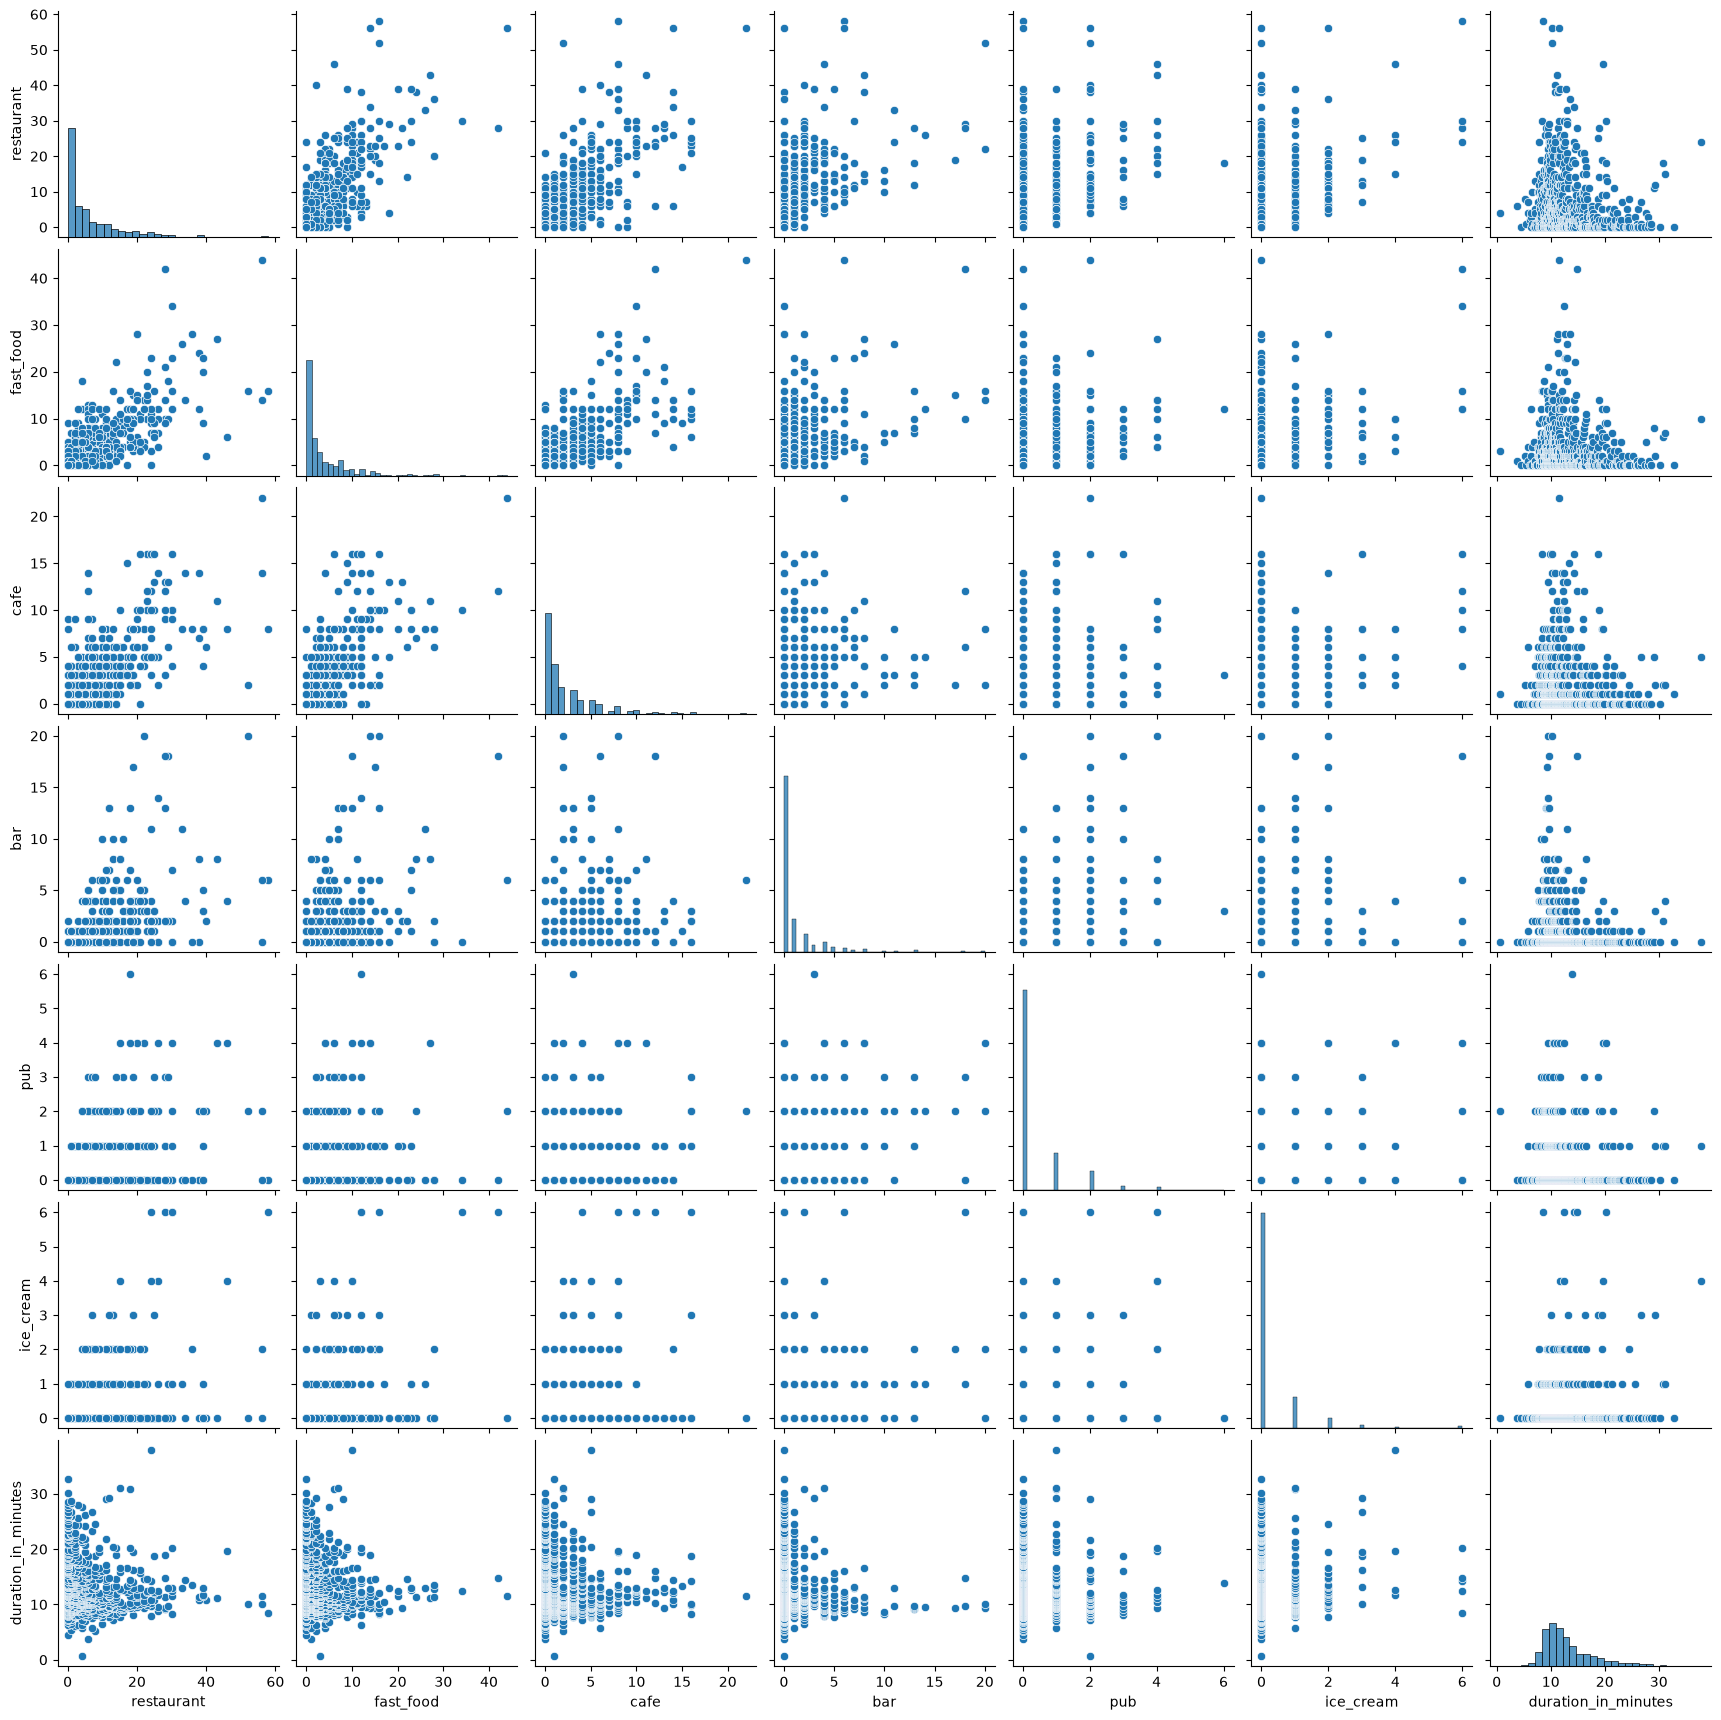

In [51]:
sns.pairplot(df[['restaurant', 'fast_food',	'cafe',	'bar', 'pub', 'ice_cream', 'duration_in_minutes']])
plt.show()

- при наличие следующих точек интереса связанные с едой restaurant, fast_food, cafe, bar минимальная аренда будет от 7 и максимальная не больше 15 минут
- что касаемо pub, ice_cream - этих точек в разы меньше, но минимальная аренда при наличии этих точек будет также от 7 до 15 минут

- можно сказать что точки интереса влияют на продолжительность, она не будет максимальной например 30 минут, но самих аренд велосипеда будет больше, чем если эти точек с едой не будет совсем

In [52]:
df

,start_station_id,restaurant,fast_food,cafe,bar,pub,ice_cream,duration_in_minutes
491,31980,4.0,3.0,1.0,0.0,2.0,0.0,0.650000
538,32065,6.0,1.0,0.0,0.0,0.0,0.0,3.691667
273,31399,0.0,0.0,0.0,0.0,0.0,0.0,4.439425
556,32204,8.0,2.0,2.0,0.0,0.0,0.0,5.166667
513,32026,1.0,0.0,0.0,0.0,0.0,0.0,5.466667
...,...,...,...,...,...,...,...,...
506,32016,0.0,0.0,0.0,0.0,0.0,0.0,30.216667
612,32406,18.0,6.0,2.0,2.0,1.0,1.0,30.841667
622,32423,15.0,7.0,2.0,4.0,1.0,1.0,31.100000
616,32415,0.0,0.0,1.0,0.0,0.0,0.0,32.741367


- строю график где выведу медианное значение duration_in_minutes разного количества restaurant, fast_food, cafe, bar, pub, ice_cream

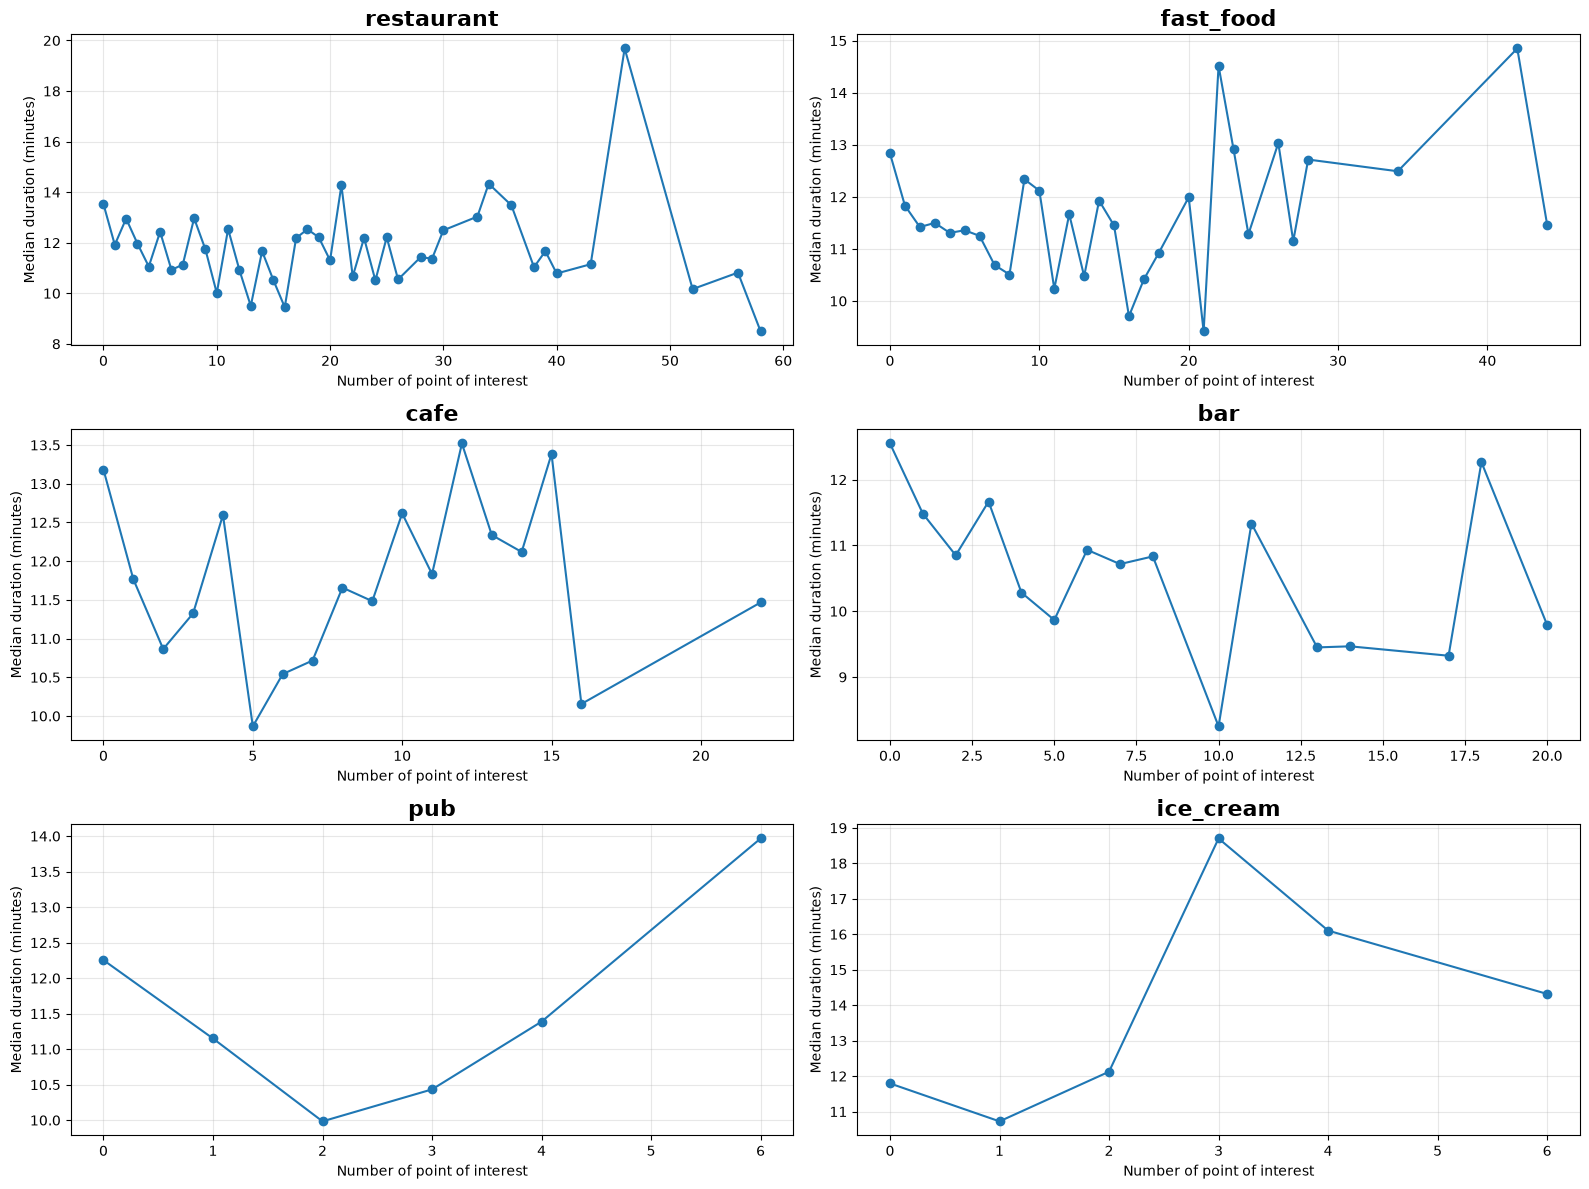

In [53]:
food_cols = ['restaurant', 'fast_food', 'cafe','bar', 'pub', 'ice_cream']

fig, axes = plt.subplots(3, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(food_cols):
    median_data = (
        df.groupby(col)['duration_in_minutes']
        .median()
        .sort_index()
    )

    axes[i].plot(
        median_data.index,
        median_data.values,
        marker='o'
    )

    axes[i].set_title(f'{col}', fontweight='bold', fontsize=16)
    axes[i].set_xlabel('Number of point of interest')
    axes[i].set_ylabel('Median duration (minutes)')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

- строю график где выведу суммарное время аренды в минутах, для разного количества restaurant, fast_food, cafe, bar, pub, ice_cream

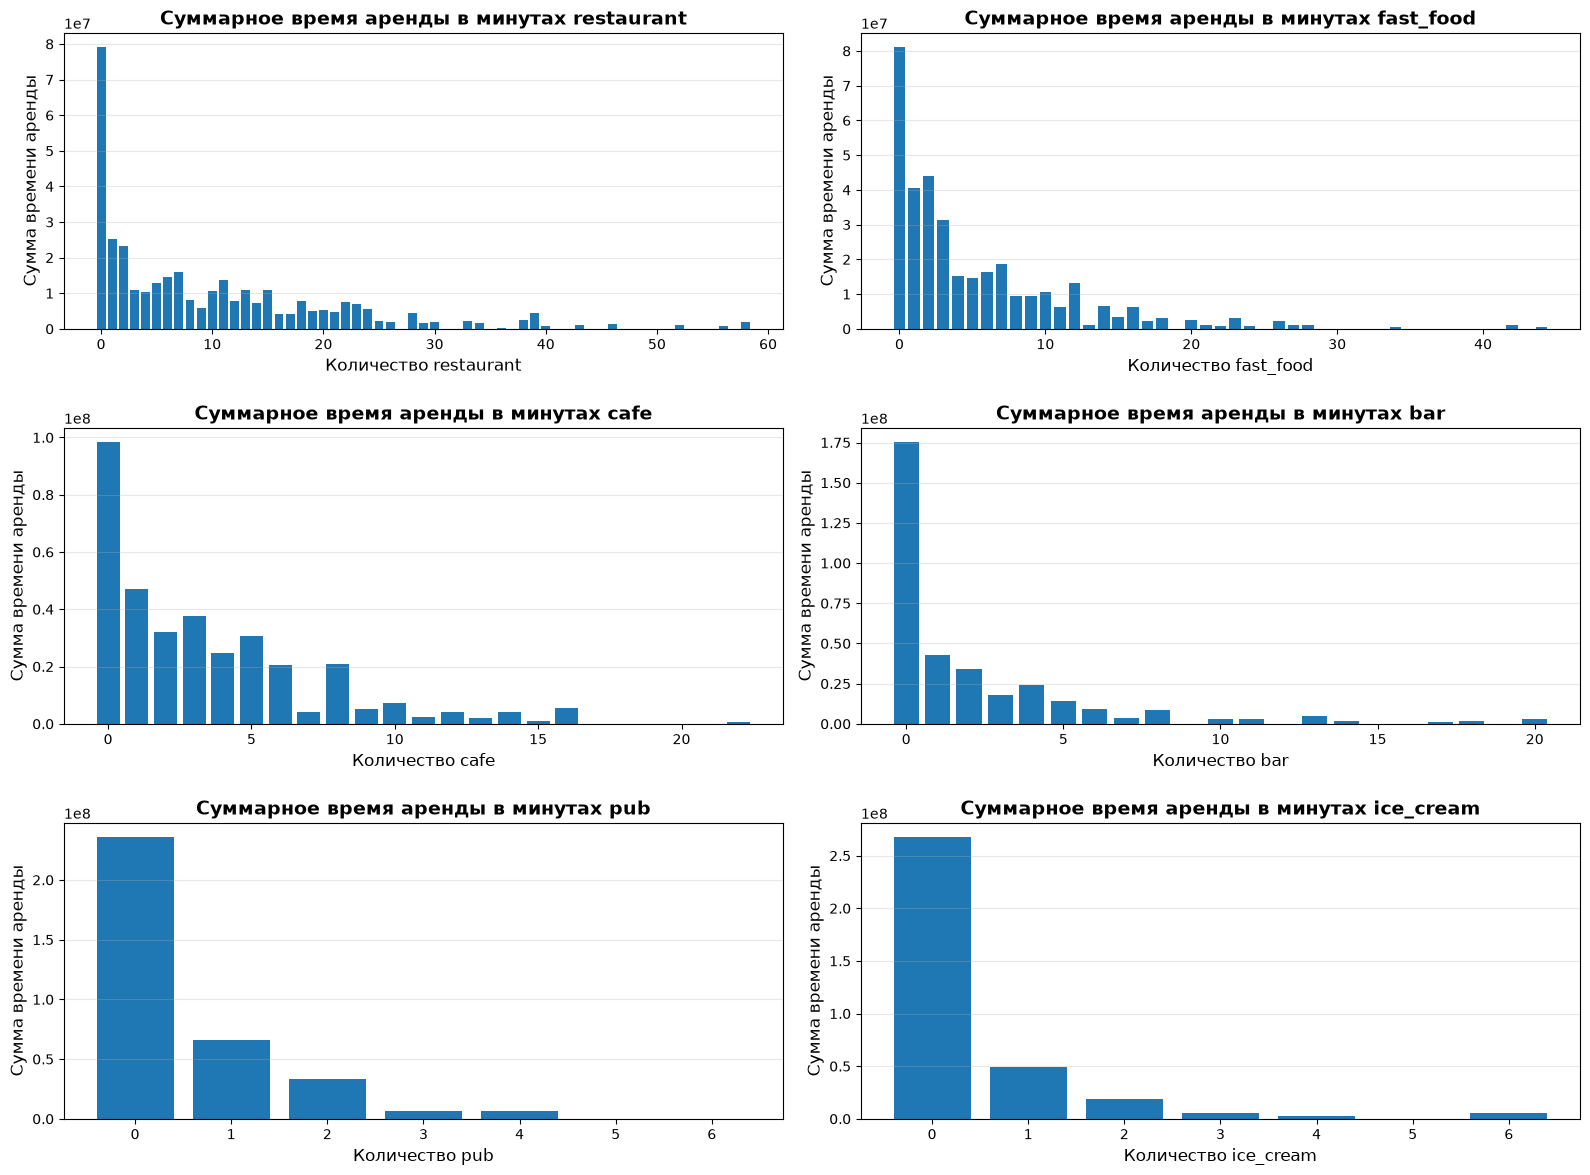

In [54]:
food_cols = ['restaurant', 'fast_food', 'cafe','bar', 'pub', 'ice_cream']

fig, axes = plt.subplots(3, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(food_cols):

    grouped_data = (
        ride_a_bike_with_food_point
        .groupby(col)['duration_in_minutes']
        .sum()
        .sort_index()
    )

    axes[i].bar(
        grouped_data.index,
        grouped_data.values
    )

    axes[i].set_xlabel(f'Количество {col}', fontsize=12)
    axes[i].set_ylabel('Сумма времени аренды', fontsize=12)
    axes[i].set_title(
        f'Суммарное время аренды в минутах {col}',
        fontsize=14,
        fontweight='bold'
    )

    axes[i].tick_params(axis='both', labelsize=10)
    axes[i].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

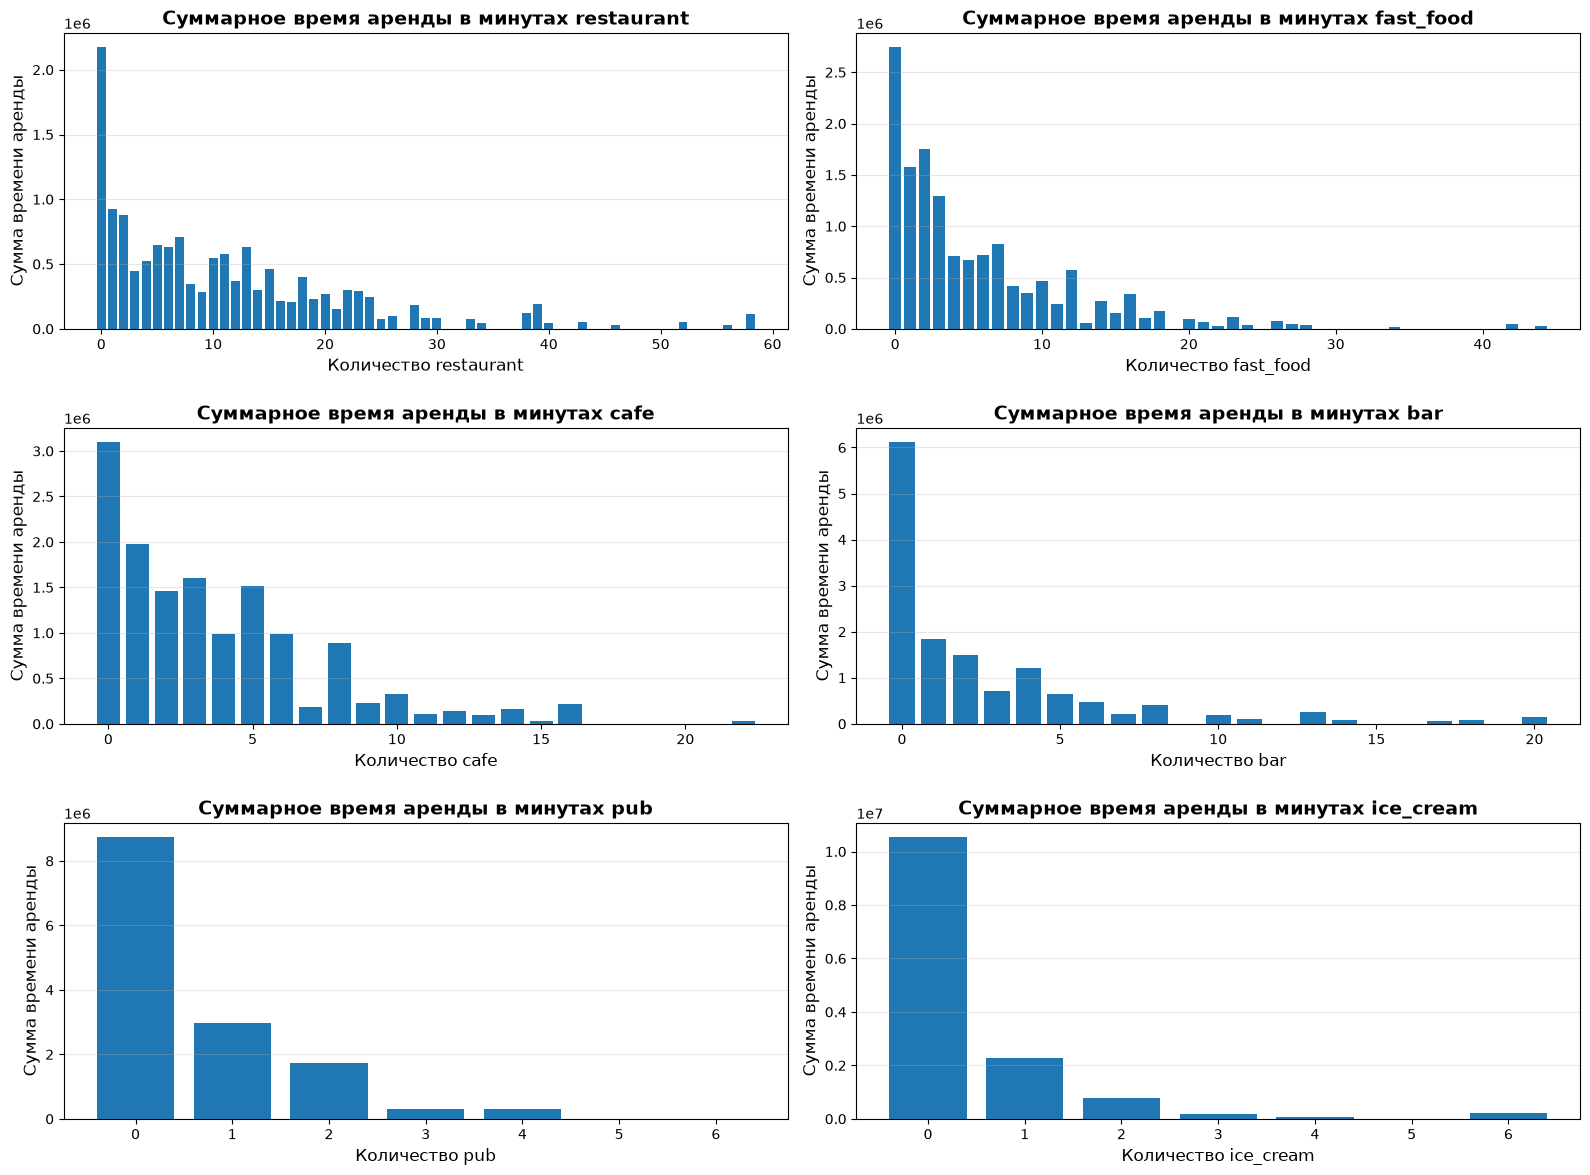

In [59]:
food_cols = ['restaurant', 'fast_food', 'cafe','bar', 'pub', 'ice_cream']

fig, axes = plt.subplots(3, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(food_cols):

    grouped_data = (
        ride_a_bike_with_food_point
        .groupby(col)['duration_in_minutes']
        .count()
        .sort_index()
    )

    axes[i].bar(
        grouped_data.index,
        grouped_data.values
    )

    axes[i].set_xlabel(f'Количество {col}', fontsize=12)
    axes[i].set_ylabel('Сумма времени аренды', fontsize=12)
    axes[i].set_title(
        f'Суммарное время аренды в минутах {col}',
        fontsize=14,
        fontweight='bold'
    )

    axes[i].tick_params(axis='both', labelsize=10)
    axes[i].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
food_cols = ['restaurant', 'fast_food', 'cafe','bar', 'pub', 'ice_cream']

result = (
    ride_a_bike_with_food_point[food_cols]
        .gt(0)                                   
        .apply(lambda s: s.value_counts())
        .reindex([False, True])                  
        .fillna(0)
        .astype(int)
        .rename(index={False: 'without', True: 'with'})
)

shares = round((result / result.sum()) * 100, 2)

result_all = pd.concat({'count': result, 'share': shares}, axis=1)
result_all

count                                                      share  \
        restaurant fast_food      cafe      bar      pub ice_cream restaurant   
without    2176026   2747070   3099879  6120864  8744223  10547812      15.49   
with      11872171  11301127  10948318  7927333  5303974   3500385      84.51   

                                                  
        fast_food   cafe    bar    pub ice_cream  
without     19.55  22.07  43.57  62.24     75.08  
with        80.45  77.93  56.43  37.76     24.92

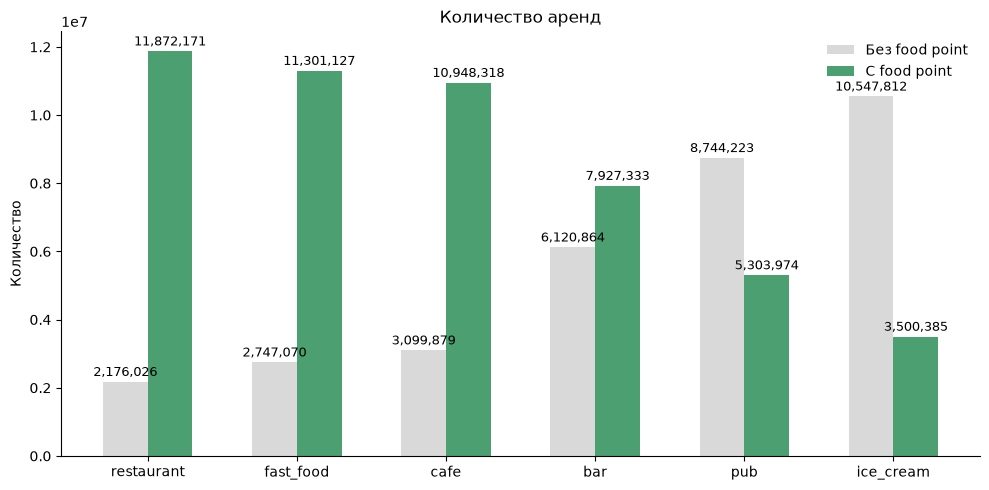

In [87]:
order = shares.loc['with'].sort_values(ascending=False).index

x = np.arange(len(order))
width = 0.3

fig, ax = plt.subplots(figsize=(10, 5))

bars_without = ax.bar(
    x - width / 2,
    result.loc['without', order],
    width=width,
    label='Без food point',
    color='#D9D9D9',
)

bars_with = ax.bar(
    x + width / 2,
    result.loc['with', order],
    width=width,
    label='С food point',
    color='#4C9F70',
)

ax.bar_label(bars_without, fmt='{:,.0f}'.format, fontsize=9, padding=2)
ax.bar_label(bars_with, fmt='{:,.0f}'.format, fontsize=9, padding=2)

ax.set_xticks(x)
ax.set_xticklabels(order)

ax.set_title('Количество аренд')
ax.set_ylabel('Количество')
ax.set_xlabel('')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)

fig.tight_layout()
plt.show()


### Вывод по гипотезе 3 - Можно ли увеличить количество аренды велосипедов, если будет путь по разным food trip.

- Если распологать точки где пользователи будут брать велосипеды где есть рестораны, фаст фуд, кафе, бар, паб, мороженное
    - для ресторанов, фаст фуд, кафе количество аренды будет более чем в 3 раза больше чем если этих точек совсем не будет

Точки интереса будут притягивать людей по разным причинам (будто еда, ПВЗ, магазины или другие)
Также количество аренд будет в разы выше чем если точек с едой совсем не будет

Здесь не проводился анализ другие точкек интереса